<a href="https://colab.research.google.com/github/fadhelhusen/pm-turi4-clustering/blob/main/PM_Pertemuan9_Praktikum_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [72]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

data = {
    'usia': [25, 34, 46, 55, 23, 40, 60, 29],
    'pendapatan': [15, 30, 45, 60, 18, 52, 65, 22],
    'skor_belanja': [39, 81, 6, 40, 76, 50, 14, 90]
}
df = pd.DataFrame(data)

In [73]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
# df berisi usia, pendapatan, skor_belanja (tanpa label)
X_scaled = StandardScaler().fit_transform(df)

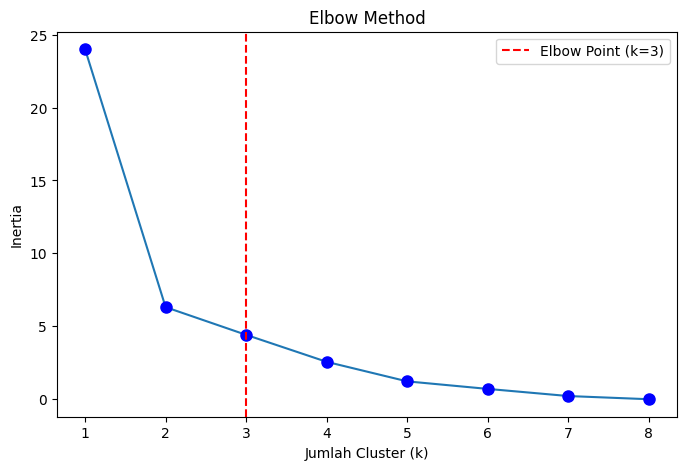

In [74]:
from sklearn.cluster import KMeans
inertias = []
# Batasi jumlah cluster maksimal sesuai dengan jumlah sampel yang tersedia
max_clusters = min(len(X_scaled), 10)

for k in range(1, max_clusters + 1):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, max_clusters + 1), inertias, marker='o', markerfacecolor='blue', markeredgecolor='blue', markersize=8)

elbow_k = 3
plt.axvline(x=elbow_k, color='red', linestyle='--', label=f'Elbow Point (k={elbow_k})')

plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.legend()
plt.show()

In [75]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
0    4
1    3
2    1
Name: count, dtype: int64


In [76]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.40564016739082154


In [77]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil

         usia  pendapatan  skor_belanja
cluster                                
0        50.2        55.5          27.5
1        28.7        23.3          82.3
2        25.0        15.0          39.0


LATIHAN MANDIRI

6.

In [78]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Menghitung Silhouette Score untuk K=3
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_3 = kmeans_3.fit_predict(X_scaled)
sil_3 = silhouette_score(X_scaled, labels_3)

# 2. Menghitung Silhouette Score untuk K=5
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_5 = kmeans_5.fit_predict(X_scaled)
sil_5 = silhouette_score(X_scaled, labels_5)

# Menampilkan hasil perbandingan
print(f"Silhouette Score untuk K=3: {sil_3:.4f}")
print(f"Silhouette Score untuk K=5: {sil_5:.4f}")

if sil_3 > sil_5:
    print("\nKesimpulan: K=3 memiliki silhouette score yang lebih baik dibandingkan K=5.")
elif sil_5 > sil_3:
    print("\nKesimpulan: K=5 memiliki silhouette score yang lebih baik dibandingkan K=3.")
else:
    print("\nKesimpulan: Kedua nilai K memiliki silhouette score yang sama.")

Silhouette Score untuk K=3: 0.4056
Silhouette Score untuk K=5: 0.2468

Kesimpulan: K=3 memiliki silhouette score yang lebih baik dibandingkan K=5.


7.

In [79]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Mempersiapkan data asli (tanpa scaling)
X_unscaled = df[['usia', 'pendapatan', 'skor_belanja']]

# Menjalankan K-Means pada data asli (K=3)
kmeans_unscaled = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_unscaled = kmeans_unscaled.fit_predict(X_unscaled)
sil_unscaled = silhouette_score(X_unscaled, labels_unscaled)

# Menampilkan perbandingan
print(f"Silhouette Score TANPA Scaling (K=3): {sil_unscaled:.4f}")
print(f"Silhouette Score DENGAN Scaling (K=3): {sil_3:.4f}")

# Kesimpulan
print("\nKesimpulan:")
if sil_3 > sil_unscaled:
    print("Scaling menghasilkan silhouette score yang LEBIH BAIK karena menyamakan rentang/skala antar fitur, sehingga mencegah satu fitur mendominasi perhitungan jarak.")
else:
    print("Pada data ini, tanpa scaling menghasilkan score yang lebih tinggi. Namun secara teoretis, scaling tetap direkomendasikan jika rentang nilai fitur berbeda jauh agar klasterisasi lebih adil.")

Silhouette Score TANPA Scaling (K=3): 0.4173
Silhouette Score DENGAN Scaling (K=3): 0.4056

Kesimpulan:
Pada data ini, tanpa scaling menghasilkan score yang lebih tinggi. Namun secara teoretis, scaling tetap direkomendasikan jika rentang nilai fitur berbeda jauh agar klasterisasi lebih adil.


8.

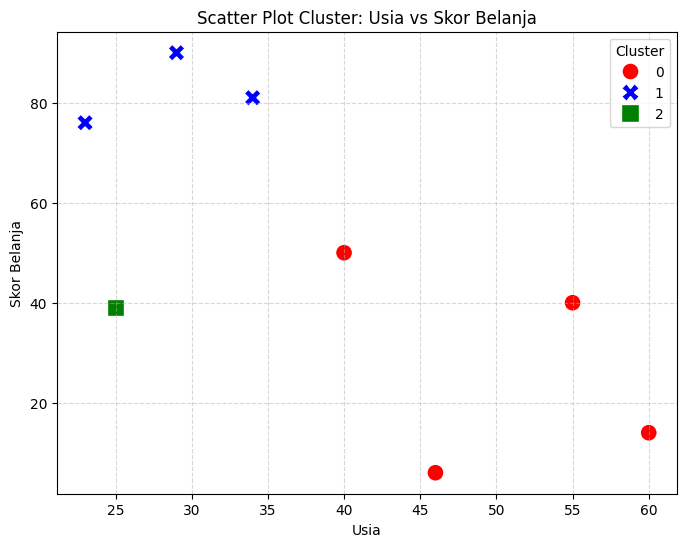

=== PENJELASAN VISUALISASI CLUSTER ===
🔴 Cluster 0 (Merah - Bulat)  : Kelompok usia tua (rata-rata 50.2 tahun) dengan pendapatan tinggi, namun memiliki skor belanja rendah.
🔵 Cluster 1 (Biru - Silang)  : Kelompok usia muda (rata-rata 28.7 tahun) dengan pendapatan rendah, tetapi memiliki skor belanja sangat tinggi.
🟢 Cluster 2 (Hijau - Kotak)  : Kelompok usia paling muda (rata-rata 25.0 tahun) dengan pendapatan terendah dan skor belanja menengah.


In [80]:
import seaborn as sns
import matplotlib.pyplot as plt

# Menentukan warna (Merah, Biru, Hijau) dan bentuk (Bulat, Silang, Kotak) secara eksplisit untuk tiap cluster
colors = {0: 'red', 1: 'blue', 2: 'green'}
markers = {0: 'o', 1: 'X', 2: 's'}  # 'o' = Bulat, 'X' = Silang, 's' = Kotak (Square)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x='usia',
    y='skor_belanja',
    hue='cluster',
    style='cluster',
    palette=colors,
    markers=markers,
    data=df,
    s=150
)

plt.title('Scatter Plot Cluster: Usia vs Skor Belanja')
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Cluster')
plt.show()

# Penjelasan arti marker dan warna
print("=== PENJELASAN VISUALISASI CLUSTER ===")
print("🔴 Cluster 0 (Merah - Bulat)  : Kelompok usia tua (rata-rata 50.2 tahun) dengan pendapatan tinggi, namun memiliki skor belanja rendah.")
print("🔵 Cluster 1 (Biru - Silang)  : Kelompok usia muda (rata-rata 28.7 tahun) dengan pendapatan rendah, tetapi memiliki skor belanja sangat tinggi.")
print("🟢 Cluster 2 (Hijau - Kotak)  : Kelompok usia paling muda (rata-rata 25.0 tahun) dengan pendapatan terendah dan skor belanja menengah.")

REFLEKSI

9. K-Means menemukan kelompok tanpa label dengan mengukur jarak dari setiap data ke titik pusat (centroid) secara berulang untuk mengelompokkannya berdasarkan kemiripan fitur. Algoritma memulainya dengan menempatkan K centroid secara acak, menetapkan setiap titik data ke centroid terdekat, lalu menggeser centroid ke posisi rata-rata anggotanya. Siklus ini terus diulang hingga posisi centroid stabil atau konvergen, sehingga struktur kelompok alami terbentuk secara otomatis tanpa memerlukan label awal.

10. Nilai inertia mengalami penurunan yang sangat tajam dari jumlah cluster satu hingga jumlah cluster tiga. Tepat pada jumlah cluster k=3 yang ditandai dengan garis vertikal merah putus-putus, kurva grafik membelok dan membentuk sudut yang menyerupai siku. Setelah melewati titik k=3 tersebut, garis grafik mulai melandai dan penurunan nilai inertia pada penambahan cluster berikutnya terjadi secara perlahan serta tidak lagi signifikan. Pola perubahan kemiringan grafik dari yang semula menurun drastis menjadi landai inilah yang membuat k=3 ditandai sebagai titik siku atau elbow point.   

11. Menurut saya, scalling sangat penting karena K-Means merupakan algoritma yang mengandalkan perhitungan jarak, sehingga standardisasi nilai diperlukan agar setiap fitur dapat berkontribusi secara adil dan seimbang. Jika scaling dilewatkan, fitur yang memiliki rentang data besar (seperti pendapatan dalam jutaan) akan mendominasi pembentukan cluster dibandingkan fitur dengan skala kecil (seperti usia). Dampaknya, perhitungan jarak antar-data menjadi terdistorsi dan sering menghasilkan pembagian cluster yang tidak akurat serta menyesatkan.